# Formative 2 - Multimodal Data Preprocessing
## Part 3: Voice Sample Collection, Augmentation and Feature Extraction

**Project component:** input data for the voiceprint verification model (the check that approves a transaction).

### Objectives
1. Load every member's recordings of the two phrases, *"Yes, approve"* and *"Confirm transaction"*.
2. Clean them so differences between phones and recording habits do not leak into the features.
3. Display each sample as a waveform and a spectrogram, and interpret them.
4. Apply six augmentations per sample.
5. Extract MFCC, spectral roll-off, energy and related features, and save them to `datasets/audio_features.csv`.

All processing code lives in [`src/audio_pipeline.py`](../src/audio_pipeline.py). The command-line demo reuses the same
functions on a new recording.

### Data layout
```
data/audio/<member>/<member>_<phrase>_<take>.<wav|aac|m4a>
```
The folder name is the speaker label. Phone formats such as AAC are decoded with ffmpeg (preinstalled on Colab).

## 1. Environment setup

In [1]:
import os
import subprocess
import sys
import warnings
from pathlib import Path

REPO_URL = "https://github.com/mutaganzwa-desire/multimodal_data_preprocessing.git"


def find_repo_root() -> Path:
    """Find the repository folder, cloning it first when running on Colab."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "src" / "audio_pipeline.py").exists():
            return folder
    if "google.colab" in sys.modules:
        target = Path("/content/multimodal_data_preprocessing")
        if not target.exists():
            subprocess.run(["git", "clone", "-q", REPO_URL, str(target)], check=True)
        return target
    raise FileNotFoundError("Open this notebook from inside the repository.")


REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)
sys.path.insert(0, str(REPO_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
print("Repository:", REPO_ROOT)

Repository: /home/rca/projects/personal/learning/alu-formative2-mlp


In [2]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from src import audio_pipeline as ap

SR = ap.SAMPLE_RATE
# Newer librosa/numba builds print a harmless cast warning inside pitch_shift;
# the output is checked for NaN and infinite values in section 8.
warnings.filterwarnings("ignore", message="invalid value encountered in cast")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 80

## 2. Clip inventory

Every member needs both phrases. Each phrase was recorded twice.

In [3]:
clips = ap.find_clips()
members = sorted(clips["member"].unique())
raw = {row.path: ap.load_audio(row.path) for row in clips.itertuples()}
clean = {path: ap.clean(y) for path, y in raw.items()}

inventory = clips.assign(
    file=clips["path"].map(lambda p: p.name),
    format=clips["path"].map(lambda p: p.suffix.lstrip(".")),
    recorded_s=clips["path"].map(lambda p: round(len(raw[p]) / SR, 2)),
    speech_s=clips["path"].map(lambda p: round(len(clean[p]) / SR, 2)),
).drop(columns="path")
display(inventory)
display(pd.crosstab(clips["member"], clips["phrase"]))

,member,phrase,take,file,format,recorded_s,speech_s
0,alain,confirm_transaction,1,alain_confirm_transaction_1.wav,wav,4.03,1.70
1,alain,confirm_transaction,2,alain_confirm_transaction_2.wav,wav,4.01,1.92
2,alain,yes_approve,1,alain_yes_approve_1.wav,wav,4.01,1.22
3,alain,yes_approve,2,alain_yes_approve_2.wav,wav,4.07,1.50
4,desire,confirm_transaction,1,desire_confirm_transaction_1.aac,aac,2.81,1.47
5,desire,confirm_transaction,2,desire_confirm_transaction_2.aac,aac,2.76,1.41
6,desire,yes_approve,1,desire_yes_approve_1.aac,aac,3.30,1.22
7,desire,yes_approve,2,desire_yes_approve_2.aac,aac,2.65,0.99


phrase,confirm_transaction,yes_approve
member,,
alain,2,2
desire,2,2


**Interpretation:** both members recorded both phrases twice, giving 8 recordings. Alain's are 4 s WAV files from one phone; Desire's are 2.6 to 3.3 s AAC files from another. After cleaning, the spoken part is 1.0 to 1.9 s for everyone, so clip length now reflects how quickly the phrase was spoken rather than how long the recorder ran.

## 3. Cleaning: keep only the spoken phrase

The two members recorded on different phones, in different formats, with different silence before and after speaking
and different loudness. If left in, a model could tell speakers apart by **clip length or volume** instead of by voice.
Each clip is therefore:

1. Decoded to mono at 16 kHz, the same rate for every device.
2. Split into sound regions (anything within 30 dB of the loudest part).
3. Regions separated by less than 0.4 s (gaps between words) are joined. The joined region with the most energy is
   kept, which drops silence and stray clicks or breaths.
4. Peak normalised to 0.95.

The shaded part of each waveform below is what is kept.

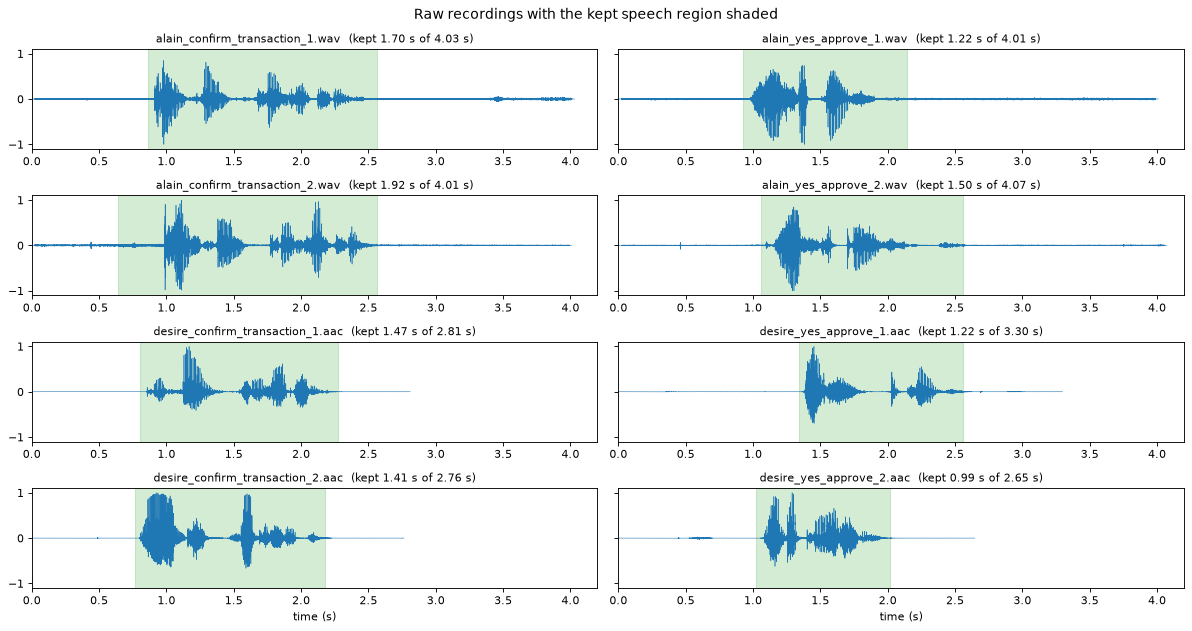

In [4]:
fig, axes = plt.subplots(len(clips) // 2, 2, figsize=(15, 2.0 * len(clips) // 2), sharey=True)
for ax, row in zip(axes.T.ravel(), clips.sort_values(["phrase", "member", "take"]).itertuples()):
    y = raw[row.path]
    start, end = ap.speech_interval(y)
    t = np.arange(len(y)) / SR
    ax.plot(t, y / (np.abs(y).max() or 1), lw=0.5, color="tab:blue")
    ax.axvspan(start / SR, end / SR, color="tab:green", alpha=0.2)
    ax.set_title(f"{row.path.name}  (kept {(end - start) / SR:.2f} s of {len(y) / SR:.2f} s)", fontsize=10)
    ax.set_xlim(0, 4.2)
for ax in axes[-1]:
    ax.set_xlabel("time (s)")
fig.suptitle("Raw recordings with the kept speech region shaded", fontsize=13)
fig.tight_layout()
plt.show()

**Interpretation:** the green region covers the whole phrase in every clip and leaves out the silence before and after it. In `alain_confirm_transaction_1.wav` and `alain_yes_approve_1.wav` a faint sound around 3.5 s, well after the phrase ends, is correctly excluded. A plain silence trim would have kept it and stretched those two clips to 2.7 s and 3.2 s of mostly silence.

## 4. Waveforms per member

Cleaned clips, all on the same time and amplitude scale.

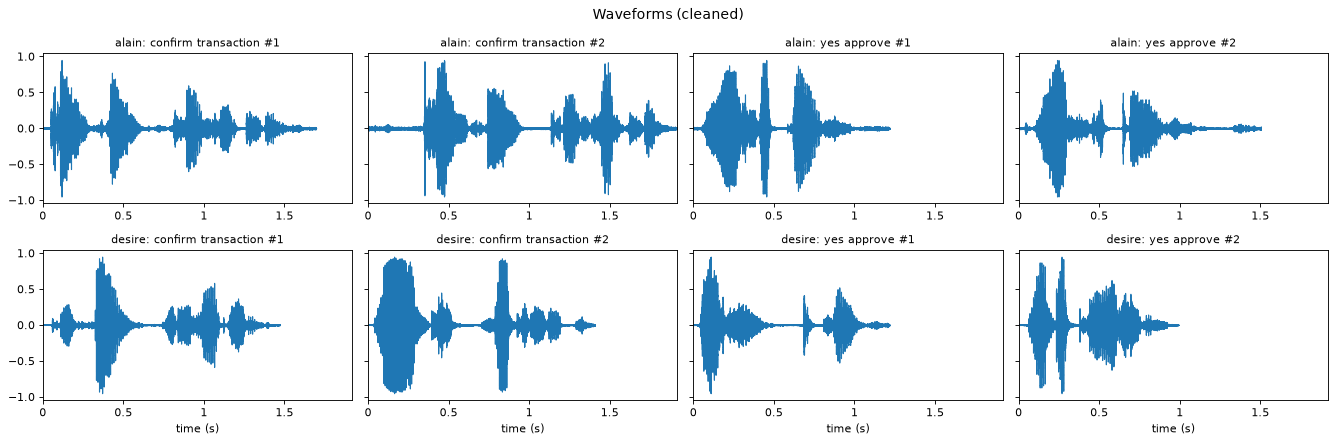

In [5]:
order = clips.sort_values(["member", "phrase", "take"])
n_cols = order.groupby("member").size().max()
longest = max(len(y) for y in clean.values()) / SR

fig, axes = plt.subplots(len(members), n_cols, figsize=(4.2 * n_cols, 2.8 * len(members)), sharey=True)
for r, member in enumerate(members):
    for c, row in enumerate(order[order["member"] == member].itertuples()):
        ax = axes[r, c]
        librosa.display.waveshow(clean[row.path], sr=SR, ax=ax, color="tab:blue")
        ax.set_title(f"{member}: {row.phrase.replace('_', ' ')} #{row.take}", fontsize=10)
        ax.set_xlim(0, longest)
        ax.set_xlabel("time (s)" if r == len(members) - 1 else "")
fig.suptitle("Waveforms (cleaned)", fontsize=13)
fig.tight_layout()
plt.show()

**Interpretation:** "Confirm transaction" shows four or five bursts, one per syllable (con-firm-trans-ac-tion), while "Yes, approve" shows a strong burst for "yes", a short pause, then "approve". Desire speaks a little faster (1.0 to 1.5 s per phrase, against 1.2 to 1.9 s for Alain). Desire's second "confirm transaction" starts with a very loud, flat-looking first word: the phone's automatic level control compressed it. The decoded file has only 3 samples at its peak, so it is not digitally clipped and is kept. Alain's `confirm_transaction #2` contains one sharp click at about 0.35 s, which barely affects the frame-averaged features.

## 5. Spectrograms per member

Mel spectrograms in decibels. Time runs left to right, pitch from bottom to top, and brighter means louder.

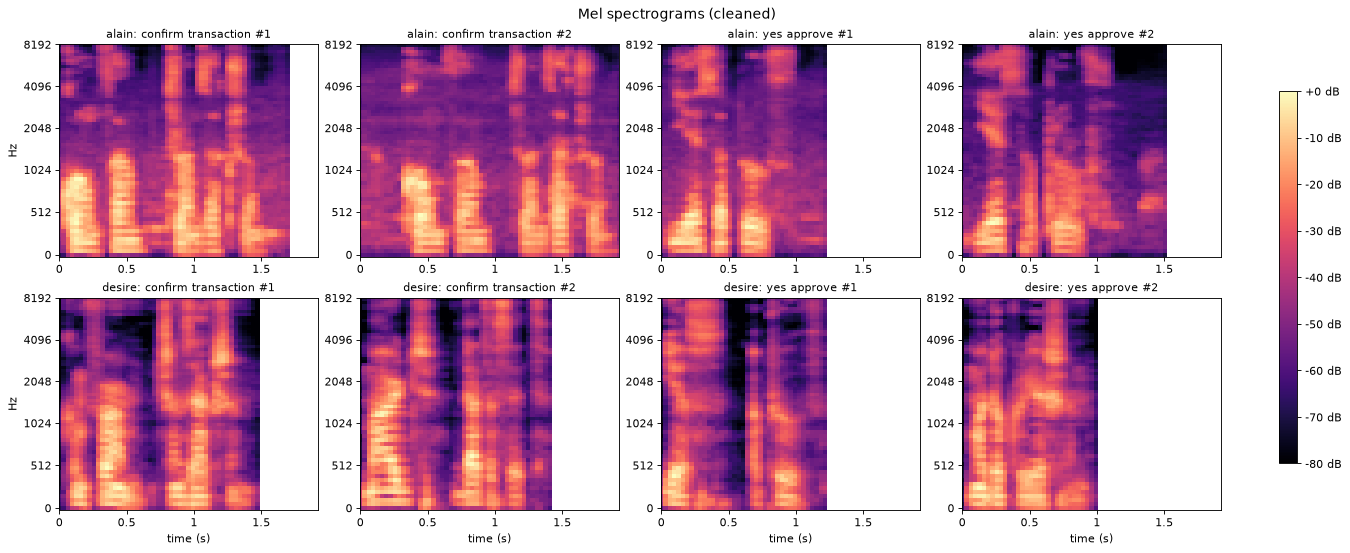

In [6]:
fig, axes = plt.subplots(len(members), n_cols, figsize=(4.2 * n_cols, 3.4 * len(members)), layout="constrained")
for r, member in enumerate(members):
    for c, row in enumerate(order[order["member"] == member].itertuples()):
        ax = axes[r, c]
        mel = librosa.feature.melspectrogram(y=clean[row.path], sr=SR, n_mels=64)
        img = librosa.display.specshow(librosa.power_to_db(mel, ref=np.max), sr=SR, x_axis="time",
                                       y_axis="mel", ax=ax, cmap="magma", vmin=-80, vmax=0)
        ax.set_title(f"{member}: {row.phrase.replace('_', ' ')} #{row.take}", fontsize=10)
        ax.set_xlim(0, longest)
        ax.set_xlabel("time (s)" if r == len(members) - 1 else "")
        ax.set_ylabel("Hz" if c == 0 else "")
fig.colorbar(img, ax=axes, format="%+2.0f dB", shrink=0.8)
fig.suptitle("Mel spectrograms (cleaned)", fontsize=13)
plt.show()

**Interpretation:** the bright horizontal bands below about 1 kHz are the harmonics and formants of the vowels, and the vertical streaks reaching above 4 kHz are consonants such as "s" and "f". For the same phrase both speakers show the same syllable pattern (the content), while the spacing and brightness of the low bands differ (the voice), which is what MFCCs capture.

One difference has nothing to do with the voice: between words Desire's clips drop to black (a noise floor of about -60 to -70 dBFS), while Alain's keep a faint purple floor (about -47 to -51 dBFS). That comes from the different phones and the AAC encoder, which removes quiet background noise. The `background_noise` augmentation below partly hides this difference, and it is listed as a limitation in the summary.

Listen to one cleaned clip per member:

In [7]:
for member in members:
    row = order[order["member"] == member].iloc[0]
    print(f"{member}: {row['path'].name}")
    display(Audio(clean[row["path"]], rate=SR))

alain: alain_confirm_transaction_1.wav


desire: desire_confirm_transaction_1.aac


## 6. Augmentation

Each cleaned clip gets **6 augmentations** plus the original, giving 7 versions per recording. Each one imitates a way the
same person may sound at login time:

| Augmentation | Imitates |
|---|---|
| `pitch_up_2st`, `pitch_down_2st` | voice slightly higher or lower (tired, excited, a cold) |
| `time_stretch_fast`, `time_stretch_slow` | speaking 15% faster or slower |
| `background_noise` | a noisy room (white noise at 20 dB SNR) |
| `gain_down_6db` | holding the phone further away |

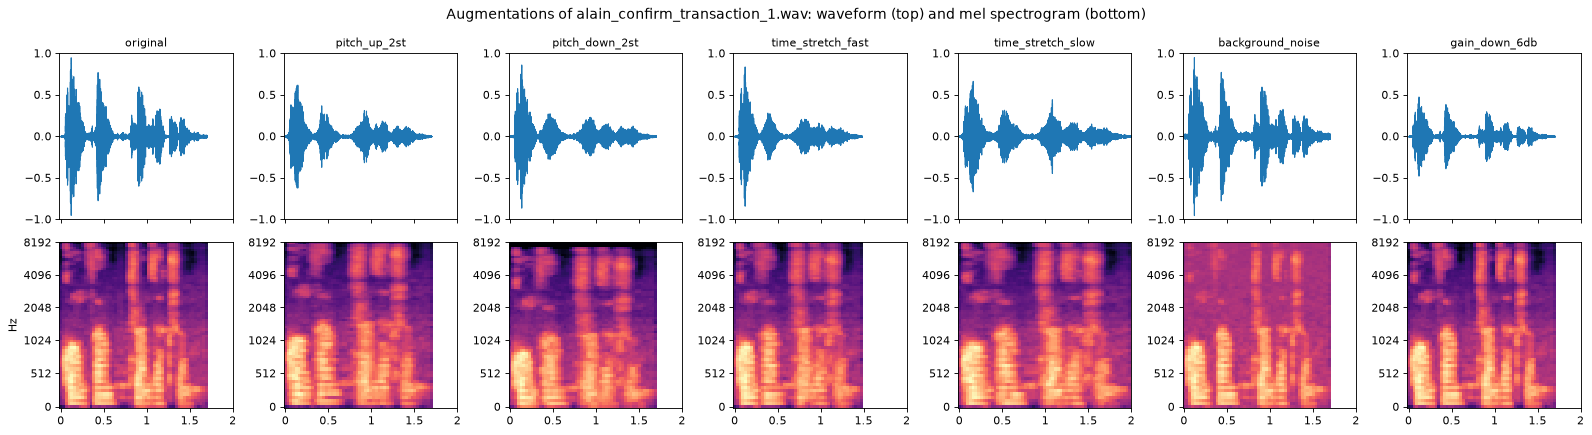

original


pitch_up_2st


pitch_down_2st


time_stretch_fast


time_stretch_slow


background_noise


gain_down_6db


In [8]:
example = order.iloc[0]["path"]
versions = ap.augment(clean[example])

fig, axes = plt.subplots(2, len(versions), figsize=(20, 5.5), sharex=True)
for c, (name, y) in enumerate(versions.items()):
    librosa.display.waveshow(y, sr=SR, ax=axes[0, c], color="tab:blue")
    axes[0, c].set_ylim(-1, 1)
    axes[0, c].set_title(name, fontsize=10)
    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=64)
    librosa.display.specshow(librosa.power_to_db(mel, ref=np.max), sr=SR, x_axis="time", y_axis="mel",
                             ax=axes[1, c], cmap="magma", vmin=-80, vmax=0)
    for ax in axes[:, c]:
        ax.set_xlabel("")
        if c:
            ax.set_ylabel("")
fig.suptitle(f"Augmentations of {example.name}: waveform (top) and mel spectrogram (bottom)", fontsize=13)
fig.tight_layout()
plt.show()

for name, y in versions.items():
    print(name)
    display(Audio(y, rate=SR, normalize=False))

**Interpretation:** the pitch shifts move the harmonic bands up or down without changing the timing. Time stretching changes the length (1.47 s and 2.00 s instead of 1.70 s) without changing the pitch. Background noise fills the gaps between words and the top of the spectrogram with an even floor. The gain change only lowers the waveform, so its spectrogram (shown relative to its own peak) looks the same and only the energy features, `rms_energy_*` and `mfcc_1_*`, change. Together they teach the voiceprint model that a slightly different-sounding version of the same person is still that person.

## 7. Feature extraction

Each version is summarised as 50 fixed-length features. Features are computed per 32 ms frame and then
summarised over time with the mean and standard deviation, so clips of any length give the same columns.

| Feature | Columns | What it captures |
|---|---|---|
| MFCC 1-13 | `mfcc_k_mean`, `mfcc_k_std` | shape of the vocal tract: the core voiceprint |
| MFCC deltas | `mfcc_delta_k_std` | how quickly that shape changes while speaking |
| Spectral roll-off | `spectral_rolloff_mean/std` | frequency below which 85% of the energy sits |
| Spectral centroid, bandwidth | `spectral_centroid_*`, `spectral_bandwidth_*` | brightness and spread of the voice |
| RMS energy | `rms_energy_mean/std` | loudness and its variation (speech rhythm) |
| Zero-crossing rate | `zcr_mean/std` | noisiness or breathiness |
| Duration | `duration_s` | speaking speed for the phrase |

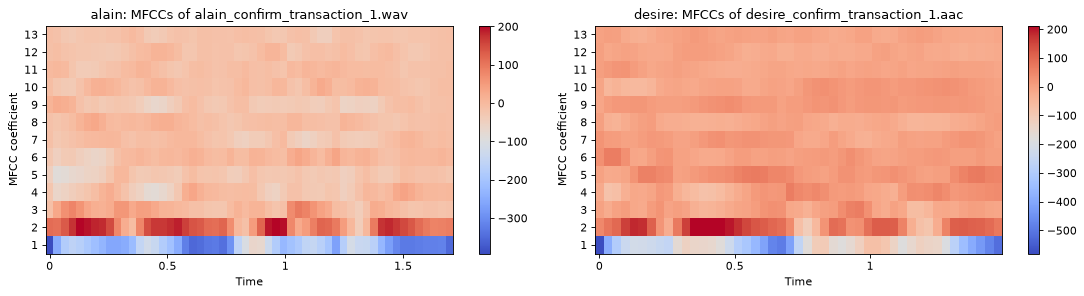

In [9]:
fig, axes = plt.subplots(1, len(members), figsize=(7 * len(members), 3.8))
for ax, member in zip(np.atleast_1d(axes), members):
    row = order[order["member"] == member].iloc[0]
    mfcc = librosa.feature.mfcc(y=clean[row["path"]], sr=SR, n_mfcc=ap.N_MFCC)
    img = librosa.display.specshow(mfcc, sr=SR, x_axis="time", ax=ax, cmap="coolwarm")
    ax.set_yticks(range(ap.N_MFCC))
    ax.set_yticklabels(range(1, ap.N_MFCC + 1))
    ax.set_ylabel("MFCC coefficient")
    ax.set_title(f"{member}: MFCCs of {row['path'].name}")
    fig.colorbar(img, ax=ax)
fig.tight_layout()
plt.show()

## 8. Build and save `audio_features.csv`

One row per (recording, augmentation). Metadata columns come first, followed by the 50 feature columns.

In [10]:
features = ap.build_feature_table()
features.to_csv(ap.OUTPUT_CSV, index=False, float_format="%.6f")

feature_cols = ap.feature_columns(features)
print(f"Saved {ap.OUTPUT_CSV.relative_to(REPO_ROOT)}: {features.shape[0]} rows, "
      f"{len(ap.METADATA_COLUMNS)} metadata columns, {len(feature_cols)} feature columns")
display(features.head(8))

Saved datasets/audio_features.csv: 56 rows, 6 metadata columns, 50 feature columns


,clip_id,member,phrase,take,augmentation,source_clip,duration_s,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,...,spectral_rolloff_mean,spectral_rolloff_std,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,spectral_bandwidth_std,rms_energy_mean,rms_energy_std,zcr_mean,zcr_std
0,alain_confirm_transaction_1__original,alain,confirm_transaction,1,original,data/audio/alain/alain_confirm_transaction_1.wav,1.696000,-226.911224,82.257217,111.932068,...,3157.986111,2008.502923,1730.953667,1097.033327,1595.313575,523.569451,0.074028,0.053809,0.149559,0.113507
1,alain_confirm_transaction_1__pitch_up_2st,alain,confirm_transaction,1,pitch_up_2st,data/audio/alain/alain_confirm_transaction_1.wav,1.696000,-239.136200,80.440323,105.330902,...,3500.578704,2098.672293,1860.364872,999.509704,1754.864799,529.680495,0.052800,0.039951,0.158565,0.114504
2,alain_confirm_transaction_1__pitch_down_2st,alain,confirm_transaction,1,pitch_down_2st,data/audio/alain/alain_confirm_transaction_1.wav,1.696000,-255.210526,79.621788,121.950630,...,2980.179398,1731.052556,1579.137452,838.376397,1528.477427,437.280573,0.055597,0.046296,0.137144,0.099401
3,alain_confirm_transaction_1__time_stretch_fast,alain,confirm_transaction,1,time_stretch_fast,data/audio/alain/alain_confirm_transaction_1.wav,1.474813,-238.398209,82.703987,106.394279,...,3411.735372,1947.716524,1773.587689,895.252597,1746.832645,489.537354,0.054812,0.044454,0.147980,0.099546
4,alain_confirm_transaction_1__time_stretch_slow,alain,confirm_transaction,1,time_stretch_slow,data/audio/alain/alain_confirm_transaction_1.wav,1.995313,-243.881317,80.675224,107.828453,...,3313.740079,2036.037364,1772.040185,994.336857,1693.498040,519.451207,0.054239,0.041705,0.150158,0.113652
5,alain_confirm_transaction_1__background_noise,alain,confirm_transaction,1,background_noise,data/audio/alain/alain_confirm_transaction_1.wav,1.696000,-151.962662,49.284172,60.168915,...,5069.155093,1688.362080,2571.791861,954.334493,2196.058827,318.525525,0.075022,0.053107,0.225948,0.108169
6,alain_confirm_transaction_1__gain_down_6db,alain,confirm_transaction,1,gain_down_6db,data/audio/alain/alain_confirm_transaction_1.wav,1.696000,-294.793488,82.257210,111.932068,...,3157.986111,2008.502923,1730.953674,1097.033325,1595.313584,523.569442,0.037102,0.026968,0.149559,0.113507
7,alain_confirm_transaction_2__original,alain,confirm_transaction,2,original,data/audio/alain/alain_confirm_transaction_2.wav,1.920000,-202.905411,70.125206,92.215836,...,3840.420082,1880.463703,2029.988436,1062.333529,1778.938032,417.374328,0.082075,0.067230,0.187268,0.117373


In [11]:
# Validation of the saved file
saved = pd.read_csv(ap.OUTPUT_CSV)
checks = {
    "rows = recordings x versions": len(saved) == len(clips) * len(ap.AUGMENTATIONS),
    "no missing values": not saved.isna().any().any(),
    "no infinite values": bool(np.isfinite(saved[feature_cols]).all().all()),
    "unique clip_id": saved["clip_id"].is_unique,
    "every member has both phrases": bool((saved.groupby("member")["phrase"].nunique() == 2).all()),
}
display(pd.Series(checks, name="passed").to_frame())
display(pd.crosstab([saved["member"], saved["phrase"]], saved["augmentation"]))

,passed
rows = recordings x versions,True
no missing values,True
no infinite values,True
unique clip_id,True
every member has both phrases,True


augmentation                background_noise  gain_down_6db  original  pitch_down_2st  pitch_up_2st  time_stretch_fast  time_stretch_slow
member phrase                                                                                                                            
alain  confirm_transaction                 2              2         2               2             2                  2                  2
       yes_approve                         2              2         2               2             2                  2                  2
desire confirm_transaction                 2              2         2               2             2                  2                  2
       yes_approve                         2              2         2               2             2                  2                  2

## 9. How the features differ between members

Original recordings only, so augmentations do not hide the natural spread.

member                         alain   desire
mfcc_1_mean            mean  -217.56  -217.54
                       std     19.41    25.33
mfcc_2_mean            mean    94.62    82.03
                       std     12.76    19.72
mfcc_3_mean            mean    14.47    -5.50
                       std      4.72    16.03
spectral_centroid_mean mean  1974.53  2080.17
                       std    198.79   388.73
spectral_rolloff_mean  mean  3687.14  3712.90
                       std    403.99   714.92
rms_energy_mean        mean     0.08     0.08
                       std      0.02     0.02
zcr_mean               mean     0.18     0.18
                       std      0.03     0.05
duration_s             mean     1.58     1.27
                       std      0.30     0.22

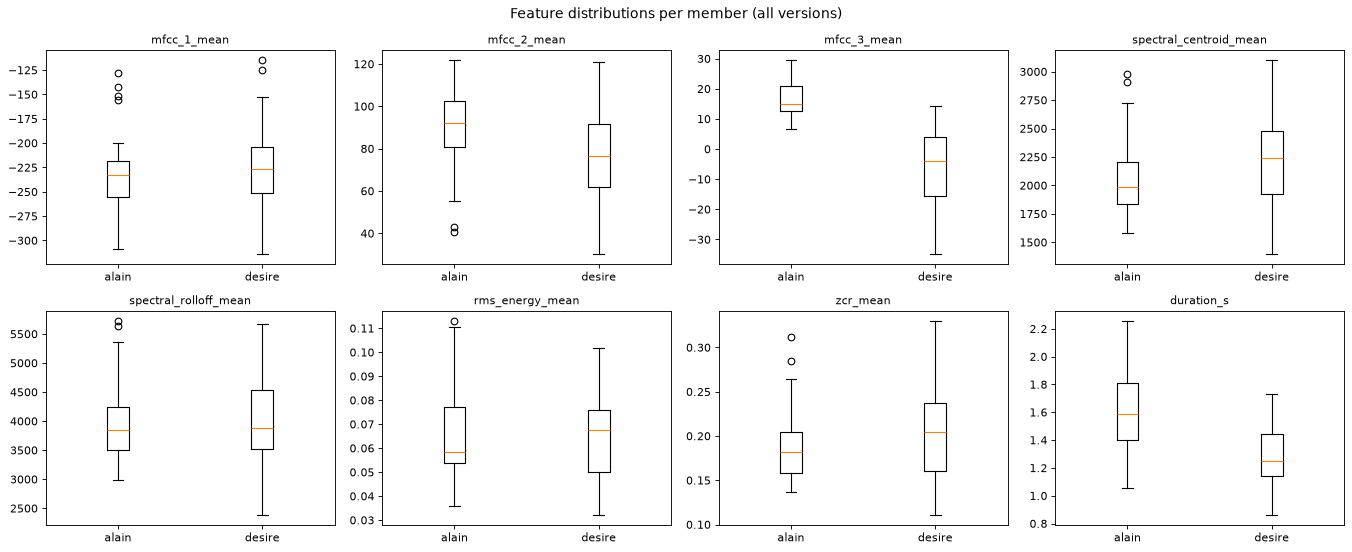

In [12]:
summary_features = ["mfcc_1_mean", "mfcc_2_mean", "mfcc_3_mean", "spectral_centroid_mean",
                    "spectral_rolloff_mean", "rms_energy_mean", "zcr_mean", "duration_s"]
originals = saved[saved["augmentation"] == "original"]
display(originals.groupby("member")[summary_features].agg(["mean", "std"]).round(2).T)

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), summary_features):
    data = [saved.loc[saved["member"] == m, col] for m in members]
    ax.boxplot(data, tick_labels=members)
    ax.set_title(col, fontsize=10)
fig.suptitle("Feature distributions per member (all versions)", fontsize=13)
fig.tight_layout()
plt.show()

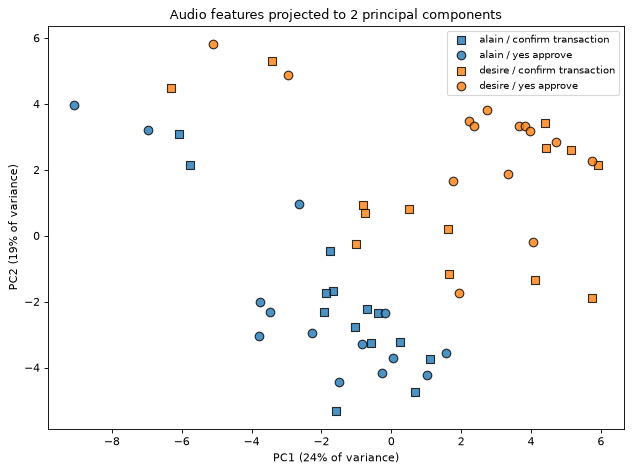

In [13]:
X = StandardScaler().fit_transform(saved[feature_cols])
pca = PCA(n_components=2, random_state=ap.SEED)
coords = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(8, 6))
markers = {"yes_approve": "o", "confirm_transaction": "s"}
colours = dict(zip(members, plt.cm.tab10.colors))
for (member, phrase), idx in saved.groupby(["member", "phrase"]).groups.items():
    ax.scatter(coords[idx, 0], coords[idx, 1], c=[colours[member]], marker=markers.get(phrase, "x"),
               s=60, alpha=0.8, edgecolor="k", label=f"{member} / {phrase.replace('_', ' ')}")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.set_title("Audio features projected to 2 principal components")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

**Identity signal check (not the final model).** Each recording is held out in turn with all 7 of its versions and
labelled with the member of its nearest neighbour among the other recordings. Holding out whole recordings avoids
matching a clip against its own augmented copies.

In [14]:
from sklearn.neighbors import KNeighborsClassifier

correct = 0
for clip in saved["source_clip"].unique():
    train, test = saved[saved["source_clip"] != clip], saved[saved["source_clip"] == clip]
    scaler = StandardScaler().fit(train[feature_cols])
    knn = KNeighborsClassifier(n_neighbors=1).fit(scaler.transform(train[feature_cols]), train["member"])
    correct += (knn.predict(scaler.transform(test[feature_cols])) == test["member"]).sum()
print(f"Leave-one-recording-out accuracy: {correct / len(saved):.2f} (chance level {1 / len(members):.2f})")

Leave-one-recording-out accuracy: 0.86 (chance level 0.50)


**Interpretation:** the first two components explain 43% of the variance. Alain's recordings (blue) sit mostly in the lower half and Desire's (orange) mostly in the upper right, with some overlap in the middle. The group in the upper left holds the `background_noise` versions of both speakers: added noise moves the spectral features more than the change of speaker does, which is exactly why it is a useful augmentation.

In the box plots, `mfcc_3_mean` separates the speakers best (about +14 for Alain and -6 for Desire on the original recordings) and `duration_s` reflects Desire's faster speech. Loudness (`rms_energy_mean`) and `spectral_rolloff_mean` overlap almost completely, as expected after peak normalisation. The nearest-neighbour check matches 0.86 of held-out versions to the right speaker, against 0.50 by chance.

## 10. Summary and notes for the voiceprint model

* **`datasets/audio_features.csv`**: 56 rows (2 members x 2 phrases x 2 takes x 7 versions), 6 metadata columns and 50 feature columns (26 MFCC mean and std, 13 MFCC delta std, roll-off, centroid, bandwidth, RMS energy, zero-crossing rate and duration). All validation checks pass.
* **Target column:** `member`. Train the voiceprint model on both phrases together; `phrase` stays available for analysis.
* **Split by `source_clip`, never by row.** The 7 versions of a recording are near copies, so use `GroupKFold` or leave-one-recording-out with `groups=source_clip`.
* **Scaling:** standardise the features for Logistic Regression; tree models do not need it.
* **At login time** call `ap.features_for_path(path)` to turn a new recording into the same 50 features, and reject it when the highest predicted probability is below a threshold.
* **Known device bias:** the two members used different phones, and Desire's codec removes background noise. A model could partly learn which phone was used rather than whose voice it is. For the unauthorised-attempt demo, record the stranger's voice on one of the team's own phones, so the test is about the voice and not the device.
* **Limitations:** 4 recordings per member is very little. More takes, ideally on the same phone for everyone, would make the voiceprint model more reliable.